Dataset shape: (400, 2)
Features: 2 non-linearly separable crescent coordinates
Number of ground-truth clusters: 2

--- Algorithm Internal Matrices ---
Adjacency Matrix Shape: (400, 400)
Laplacian Matrix Shape: (400, 400)
Top 2 Smallest Eigenvalues: [-0.  0.]


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(



--- Final Results and Metrics ---
Silhouette Score: 0.3775
Adjusted Rand Index (ARI): 1.0000 (1.0 indicates perfect separation)


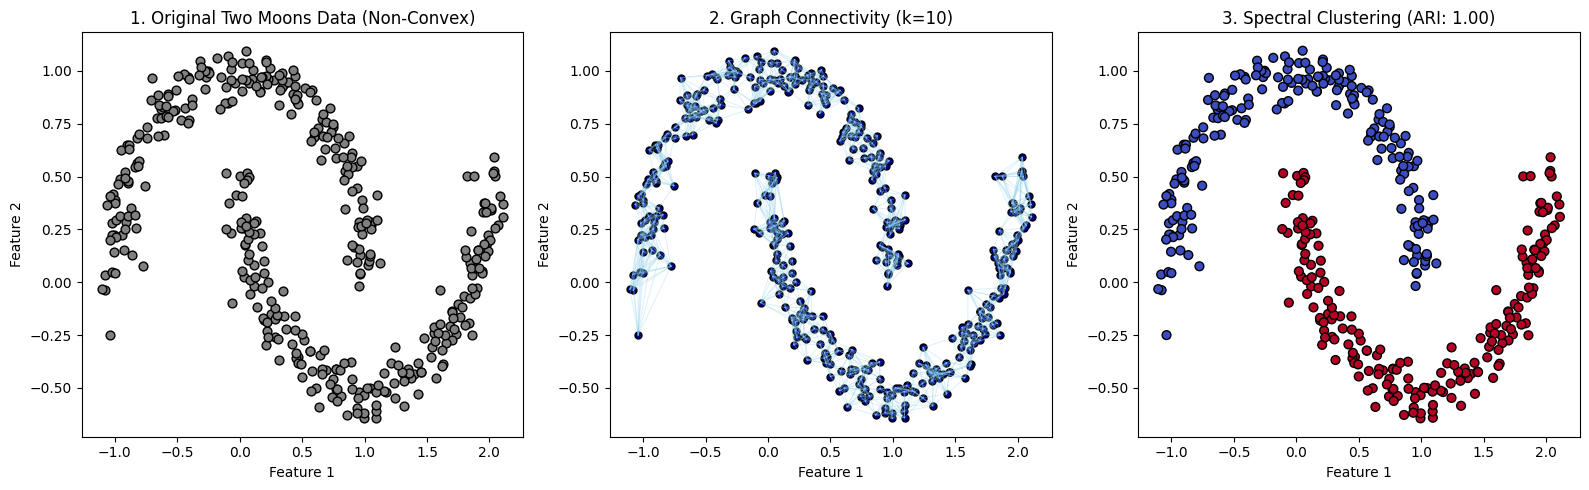

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import kneighbors_graph
from scipy.linalg import eigh

# Generate 400 data points with non-linear, crescent geometry
X, y = make_moons(n_samples=400, noise=0.07, random_state=42)

# Standardization: Centers data to zero mean and unit variance for uniform distance calculations
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dataset shape: {X_scaled.shape}")
print(f"Features: 2 non-linearly separable crescent coordinates")
print(f"Number of ground-truth clusters: {len(np.unique(y))}")

# ==============================================================================
# SECTION 3: ALGORITHM WORKING (FROM MATHEMATICAL PRINCIPLES)
# ==============================================================================
# Spectral Clustering translates data clustering into a graph-cut problem:
# 1. Represent data as an undirected graph G = (V, E) using k-nearest neighbors.
# 2. Build the Adjacency Matrix (W) and Degree Matrix (D).
# 3. Compute the Normalized Graph Laplacian: L_sym = D^(-1/2) * (D - W) * D^(-1/2).
# 4. Compute the lowest 'k' eigenvectors of L_sym to project data into a separable space.

# Step 3.1: Build k-Nearest Neighbors graph (k = 10)
k_neighbors = 10
knn_graph = kneighbors_graph(X_scaled, n_neighbors=k_neighbors, mode='connectivity', include_self=False)

# Make the adjacency matrix symmetric (undirected graph)
adjacency_matrix = 0.5 * (knn_graph + knn_graph.T).toarray()

# Step 3.2: Construct the Degree Matrix D (sum of edge weights for each node)
degree_vector = np.sum(adjacency_matrix, axis=1)
degree_matrix = np.diag(degree_vector)

# Step 3.3: Compute the Unnormalized Graph Laplacian: L = D - W
L = degree_matrix - adjacency_matrix

# Step 3.4: Compute the Symmetric Normalized Graph Laplacian: L_sym = D^(-1/2) * L * D^(-1/2)
D_inv_sqrt = np.diag(1.0 / np.sqrt(degree_vector))
L_sym = D_inv_sqrt @ L @ D_inv_sqrt

# Step 3.5: Eigendecomposition of the Laplacian matrix
eigenvalues, eigenvectors = eigh(L_sym)

# Select the first k eigenvectors corresponding to the smallest eigenvalues (k=2 for 2 clusters)
num_clusters = 2
spectral_embedding = eigenvectors[:, :num_clusters]

# Normalize rows to unit length for clustering stability
spectral_embedding_norm = spectral_embedding / np.linalg.norm(spectral_embedding, axis=1, keepdims=True)

print("\n--- Algorithm Internal Matrices ---")
print(f"Adjacency Matrix Shape: {adjacency_matrix.shape}")
print(f"Laplacian Matrix Shape: {L_sym.shape}")
print(f"Top {num_clusters} Smallest Eigenvalues: {np.round(eigenvalues[:num_clusters], 4)}")

# Apply Spectral Clustering using nearest-neighbors affinity graph
spectral_model = SpectralClustering(
    n_clusters=num_clusters,
    affinity='nearest_neighbors',
    n_neighbors=k_neighbors,
    assign_labels='kmeans',
    random_state=42
)

# Fit model and predict cluster assignments
cluster_labels = spectral_model.fit_predict(X_scaled)

sil_score = silhouette_score(X_scaled, cluster_labels)
ari_score = adjusted_rand_score(y, cluster_labels)

print("\n--- Final Results and Metrics ---")
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f} (1.0 indicates perfect separation)")

# Multi-panel visualization: Raw Data -> Graph Structure -> Final Clustered Result
plt.figure(figsize=(16, 5))

# Plot 1: Unclustered raw data
plt.subplot(1, 3, 1)
plt.scatter(X[:, 0], X[:, 1], c='gray', edgecolors='k', s=40)
plt.title("1. Original Two Moons Data (Non-Convex)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# Plot 2: Constructed k-NN affinity graph
plt.subplot(1, 3, 2)
for i in range(len(X)):
    neighbors = np.where(adjacency_matrix[i] > 0)[0]
    for j in neighbors:
        if i < j:
            plt.plot([X[i, 0], X[j, 0]], [X[i, 1], X[j, 1]], color='skyblue', alpha=0.3, linewidth=0.7)
plt.scatter(X[:, 0], X[:, 1], c='darkblue', edgecolors='k', s=25)
plt.title(f"2. Graph Connectivity (k={k_neighbors})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# Plot 3: Resulting clusters formed by Spectral Clustering
plt.subplot(1, 3, 3)
plt.scatter(X[:, 0], X[:, 1], c=cluster_labels, cmap='coolwarm', edgecolors='k', s=40)
plt.title(f"3. Spectral Clustering (ARI: {ari_score:.2f})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()